In [12]:
import xarray as xr

# 打开你的 nc 文件
ds = xr.open_dataset(r"F:\TUB\greenlandProject\ERA5LAND\2020.nc")

# 列出所有变量
print(ds.data_vars)


Data variables:
    t2m      (valid_time, latitude, longitude) float32 ...
    asn      (valid_time, latitude, longitude) float32 ...
    fal      (valid_time, latitude, longitude) float32 ...
    ssr      (valid_time, latitude, longitude) float32 ...
    str      (valid_time, latitude, longitude) float32 ...
    ssrd     (valid_time, latitude, longitude) float32 ...
    strd     (valid_time, latitude, longitude) float32 ...
    u10      (valid_time, latitude, longitude) float32 ...
    v10      (valid_time, latitude, longitude) float32 ...
    sp       (valid_time, latitude, longitude) float32 ...
    tp       (valid_time, latitude, longitude) float32 ...


In [11]:
import xarray as xr
import pandas as pd
import numpy as np

# 打开 netCDF 文件
file_path = "F:/TUB/greenlandProject/ERA5LAND/2020snowcsde.nc"
ds = xr.open_dataset(file_path)

# 提取变量和坐标
snowc = ds['snowc']
sde = ds['sde']
lat = ds['latitude']
lon = ds['longitude']
valid_time = ds['valid_time']  # 使用正确的时间维度

# 将 valid_time 转换为 pandas datetime 对象
valid_time = pd.to_datetime(valid_time.values)

# 获取时间的年份和月份
months = valid_time.to_period('M')  # 转换为年月格式

# 遍历每个月
for month in months.unique():
    # 筛选该月份的数据
    monthly_mask = months == month
    snowc_month = snowc.sel(valid_time=monthly_mask).values
    sde_month = sde.sel(valid_time=monthly_mask).values

    # 获取经纬度数据
    lat_vals = lat.values
    lon_vals = lon.values

    # 将数据转换为DataFrame
    rows = []
    for i in range(snowc_month.shape[1]):  # 遍历纬度维度
        for j in range(snowc_month.shape[2]):  # 遍历经度维度
            rows.append([lat_vals[i], lon_vals[j], snowc_month[0, i, j], sde_month[0, i, j]])

    df = pd.DataFrame(rows, columns=['latitude', 'longitude', 'snowc', 'sde'])

    # 保存为CSV文件
    month_str = str(month).replace('-', '')  # 格式化为 yyyyMM
    output_file = f"F:/TUB/greenlandProject/ERA5LAND/snowcsde/{month_str}snowcsde.csv"
    df.to_csv(output_file, index=False)

    print(f"Saved {output_file}")


Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202001snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202002snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202003snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202004snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202005snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202006snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202007snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202008snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202009snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202010snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202011snowcsde.csv
Saved F:/TUB/greenlandProject/ERA5LAND/snowcsde/202012snowcsde.csv


In [13]:
import xarray as xr
import pandas as pd
import numpy as np

# 打开 netCDF 文件
file_path = "F:/TUB/greenlandProject/ERA5LAND/2020.nc"
ds = xr.open_dataset(file_path)

# 提取变量和坐标
variables = ['sp', 'ssrd', 'str', 'strd', 't2m', 'u10', 'v10', 'asn', 'fal']
lat = ds['latitude']
lon = ds['longitude']
valid_time = ds['valid_time']  # 时间维度

# 将 valid_time 转换为 pandas datetime 对象
valid_time = pd.to_datetime(valid_time.values)

# 获取时间的年份和月份
months = valid_time.to_period('M')  # 转换为年月格式

# 遍历每个月
for month in months.unique():
    # 筛选该月份的数据
    monthly_mask = months == month
    
    # 提取各个变量的值
    data = {var: ds[var].sel(valid_time=monthly_mask).values for var in variables}

    # 获取经纬度数据
    lat_vals = lat.values
    lon_vals = lon.values

    # 将数据转换为DataFrame
    rows = []
    for i in range(data['sp'].shape[1]):  # 遍历纬度维度
        for j in range(data['sp'].shape[2]):  # 遍历经度维度
            row = [lat_vals[i], lon_vals[j]]
            # 将每个变量的值加入一行数据
            for var in variables:
                row.append(data[var][0, i, j])  # 每个变量的值按经纬度位置提取
            rows.append(row)

    # 创建 DataFrame
    columns = ['latitude', 'longitude'] + variables
    df = pd.DataFrame(rows, columns=columns)

    # 保存为CSV文件
    month_str = str(month).replace('-', '')  # 格式化为 yyyyMM
    output_file = f"F:/TUB/greenlandProject/ERA5LAND/2020/{month_str}data.csv"
    df.to_csv(output_file, index=False)

    print(f"Saved {output_file}")


Saved F:/TUB/greenlandProject/ERA5LAND/2020/202001data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202002data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202003data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202004data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202005data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202006data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202007data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202008data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202009data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202010data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202011data.csv
Saved F:/TUB/greenlandProject/ERA5LAND/2020/202012data.csv


In [15]:
import pandas as pd
import os

# 文件夹路径
folder_path = r'F:\TUB\greenlandProject\ERA5LAND\2020snowcsde'

# 获取文件夹中所有csv文件
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

# 遍历每个csv文件
for csv_file in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    # 读取csv文件
    df = pd.read_csv(file_path)
    
    # 将经度列转换为新的值，假设经度列名为 'longitude'
    df['longitude'] = df['longitude'].apply(lambda x: x - 360 if x > 180 else x)
    
    # 保存处理后的数据
    df.to_csv(file_path, index=False)

print("处理完成！")


处理完成！


In [ ]:
#---------------------------------DEM添加到----------------气象文件中-----------------------------
import os
import pandas as pd

# 路径设置
dem_file = r"F:\TUB\greenlandProject\ERA5LAND\beifen\greenland_DEM_01deg.csv"
target_dir = r"F:\TUB\greenlandProject\ERA5LAND\2020"

# 1. 加载DEM数据并检查
dem_df = pd.read_csv(dem_file)
print("DEM数据前5行:\n", dem_df.head())
dem_df['latitude'] = dem_df['latitude'].round(4)  # 解决浮点数精度问题
dem_df['longitude'] = dem_df['longitude'].round(4)

# 2. 处理目标文件
for filename in os.listdir(target_dir):
    if filename.endswith('.csv'):
        filepath = os.path.join(target_dir, filename)
        target_df = pd.read_csv(filepath)
        
        # 仅处理sp不为空的行
        valid_rows = target_df[target_df['sp'].notna()].copy()
        if valid_rows.empty:
            print(f"{filename}: 无sp有效数据，跳过")
            continue
        
        # 对坐标四舍五入（确保匹配）
        valid_rows['latitude'] = valid_rows['latitude'].round(4)
        valid_rows['longitude'] = valid_rows['longitude'].round(4)
        
        # 合并DEM数据
        merged = pd.merge(
            valid_rows,
            dem_df,
            on=['latitude', 'longitude'],
            how='left'
        )
        
        # 3. 检查合并结果
        print(f"\n文件 {filename} 合并结果:")
        print("匹配成功的行数:", merged['altitude_last_valid'].notna().sum())
        print("示例数据（前2行）:")
        print(merged[['latitude', 'longitude', 'sp', 'altitude_last_valid']].head(2))
        
        # 更新原数据（仅修改sp不为空的行）
        target_df.loc[target_df['sp'].notna(), 'altitude_last_valid'] = merged['altitude_last_valid'].values
        target_df.to_csv(filepath, index=False)

print("\n处理完成！请检查上方输出确认匹配情况。")

In [10]:
#---------------------------------2020年每个月份的snowc和sde添加到----------------气象文件中-----------------------------
import os
import pandas as pd

# 路径设置
source_dir = r"F:\TUB\greenlandProject\ERA5LAND\2020snowcsde"  # snowc/sde数据目录
target_dir = r"F:\TUB\greenlandProject\ERA5LAND\2020"          # 目标目录

# 处理每个目标文件
for target_filename in os.listdir(target_dir):
    if target_filename.endswith('.csv'):
        # 提取月份（如202001）
        month = target_filename[:6]  # 假设目标文件名为202001data.csv
        
        # 构建对应的源文件名（202001snowcsde.csv）
        source_filename = f"{month}snowcsde.csv"
        source_path = os.path.join(source_dir, source_filename)
        
        if not os.path.exists(source_path):
            print(f"警告：未找到源文件 {source_filename}，跳过 {target_filename}")
            continue
        
        # 读取数据
        target_df = pd.read_csv(os.path.join(target_dir, target_filename))
        source_df = pd.read_csv(source_path)
        
        # 检查必要列是否存在
        required_cols = ['latitude', 'longitude', 'snowc', 'sde']
        if not all(col in source_df.columns for col in required_cols):
            missing = [col for col in required_cols if col not in source_df.columns]
            print(f"错误：{source_filename} 缺少列 {missing}，跳过")
            continue
        
        # 对坐标四舍五入（解决浮点精度问题）
        for df in [target_df, source_df]:
            df['latitude'] = df['latitude'].round(6)  # 提高精度
            df['longitude'] = df['longitude'].round(6)
        
        # 合并数据
        merged_df = pd.merge(
            target_df,
            source_df[['latitude', 'longitude', 'snowc', 'sde']],
            on=['latitude', 'longitude'],
            how='left'
        )
        
        # 保存结果（覆盖原文件）
        merged_df.to_csv(os.path.join(target_dir, target_filename), index=False)
        
        # 打印处理结果
        added_snowc = merged_df['snowc'].notna().sum()
        added_sde = merged_df['sde'].notna().sum()
        print(f"成功处理 {target_filename} | 添加 snowc={added_snowc}行, sde={added_sde}行")

print("\n处理完成！请检查输出结果。")

成功处理 202001data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202002data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202003data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202004data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202005data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202006data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202007data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202008data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202009data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202010data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202011data.csv | 添加 snowc=86629行, sde=86629行
成功处理 202012data.csv | 添加 snowc=86629行, sde=86629行

处理完成！请检查输出结果。


In [12]:
#---------------------------------保留有值的气象数据行，覆盖了Grennland地区----------------------------
import os
import pandas as pd
import re

# 定义路径
path = r"F:\TUB\greenlandProject\ERA5LAND\2020"

# 遍历目录下的所有csv文件
for filename in os.listdir(path):
    if filename.endswith(".csv"):
        # 使用正则表达式提取年份和月份
        match = re.search(r"(\d{4})(\d{2})data\.csv", filename)
        if match:
            year = match.group(1)
            month = match.group(2)
            
            # 构建完整文件路径
            filepath = os.path.join(path, filename)
            
            # 读取csv文件
            df = pd.read_csv(filepath)
            
            # 检查'sp'列是否存在
            if 'sp' in df.columns:
                # 只保留sp列有值的行（非空行）
                df = df[df['sp'].notna()]
                
                # 如果过滤后DataFrame不为空
                if not df.empty:
                    # 添加year和month列
                    df['year'] = int(year)
                    df['month'] = int(month)
                    
                    # 构建新文件名
                    new_filename = f"{year}{month}input.csv"
                    new_filepath = os.path.join(path, new_filename)
                    
                    # 保存处理后的文件
                    df.to_csv(new_filepath, index=False)
                    print(f"处理完成: {filename} -> {new_filename} (保留{len(df)}行)")
                else:
                    print(f"跳过: {filename} (sp列无有效数据)")
            else:
                print(f"跳过: {filename} (无sp列)")

处理完成: 202001data.csv -> 202001input.csv (保留86629行)
处理完成: 202002data.csv -> 202002input.csv (保留86629行)
处理完成: 202003data.csv -> 202003input.csv (保留86629行)
处理完成: 202004data.csv -> 202004input.csv (保留86629行)
处理完成: 202005data.csv -> 202005input.csv (保留86629行)
处理完成: 202006data.csv -> 202006input.csv (保留86629行)
处理完成: 202007data.csv -> 202007input.csv (保留86629行)
处理完成: 202008data.csv -> 202008input.csv (保留86629行)
处理完成: 202009data.csv -> 202009input.csv (保留86629行)
处理完成: 202010data.csv -> 202010input.csv (保留86629行)
处理完成: 202011data.csv -> 202011input.csv (保留86629行)
处理完成: 202012data.csv -> 202012input.csv (保留86629行)


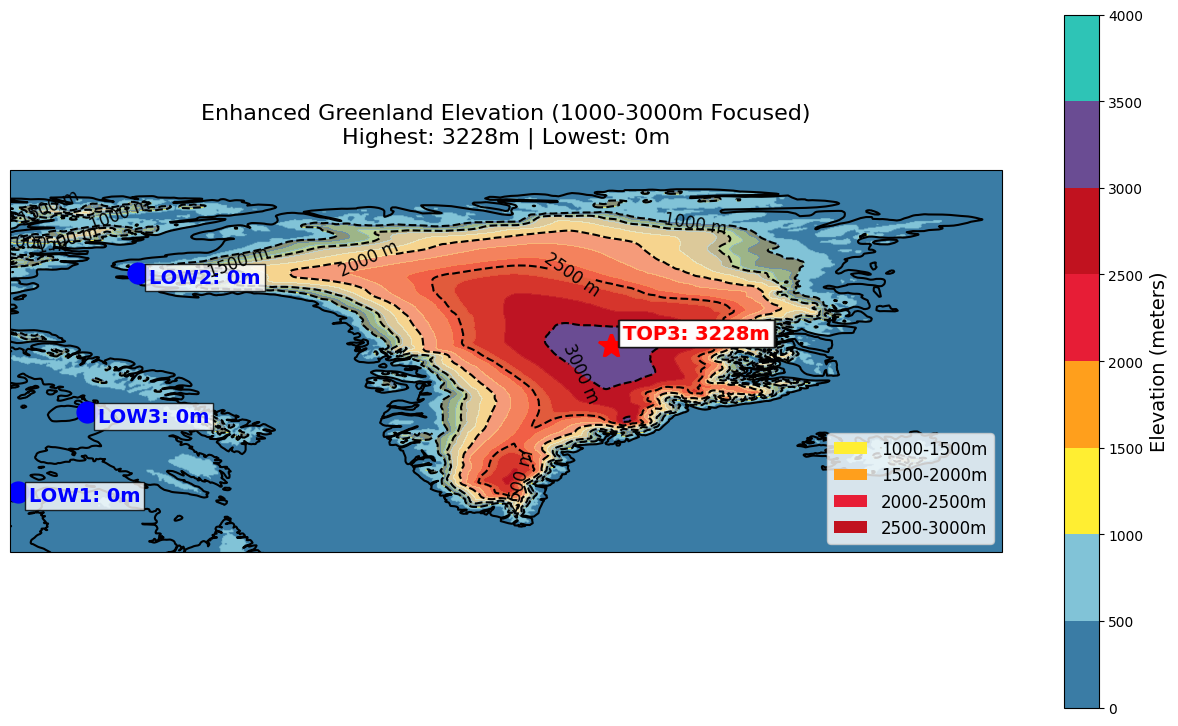

In [18]:
# ==== 修正版：解决索引越界问题 ==== #
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter

# ==== 1. 数据准备 ==== #
def load_and_process():
    ds = xr.open_dataset(r"F:\TUB\greenlandProject\ETOPO1_Ice_g_gmt4.grd\ETOPO1_Ice_g_gmt4.grd")
    dem = ds['z'].sel(x=slice(-80, -10), y=slice(58, 85))
    
    # 降采样到0.1°
    dem = dem.coarsen(x=4, y=4, boundary='trim').mean()
    
    # 平滑处理
    smoothed = gaussian_filter(dem.values, sigma=1)
    return dem.x.values, dem.y.values, smoothed

lons, lats, elevations = load_and_process()
XX, YY = np.meshgrid(lons, lats)

# ==== 2. 修正的极值点检测 ==== #
def get_extremes(elev, num=3):
    # 最高点检测
    max_flat = elev.flatten()
    max_indices = np.argpartition(max_flat, -num)[-num:]
    max_points = np.unravel_index(max_indices, elev.shape)
    
    # 最低点检测（仅陆地）
    land_mask = elev > 0
    land_elev = np.where(land_mask, elev, np.nan)
    min_flat = land_elev[~np.isnan(land_elev)]
    if len(min_flat) < num:
        num = len(min_flat)
    min_indices = np.argpartition(min_flat, num)[:num]
    
    # 获取原始数组中的位置
    valid_indices = np.argwhere(land_mask.flatten())[min_indices].flatten()
    min_points = np.unravel_index(valid_indices, elev.shape)
    
    return max_points, min_points

max_idx, min_idx = get_extremes(elevations)
max_lons, max_lats = XX[max_idx], YY[max_idx]
min_lons, min_lats = XX[min_idx], YY[min_idx]
max_vals, min_vals = elevations[max_idx], elevations[min_idx]

# ==== 3. 创建分段颜色映射 ==== #
def create_cmap():
    bounds = [0, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000]
    colors = [
        '#3A7CA5', '#81C3D7', '#FFEE32', 
        '#FF9F1C', '#E71D36', '#C1121F',
        '#6A4C93', '#2EC4B6'
    ]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(bounds, cmap.N)
    return cmap, norm

cmap, norm = create_cmap()

# ==== 4. 可视化 ==== #
plt.figure(figsize=(16, 18))
ax = plt.axes(projection=ccrs.PlateCarree())

# 高程主图
img = ax.pcolormesh(XX, YY, elevations, 
                   cmap=cmap, norm=norm,
                   shading='gouraud',
                   transform=ccrs.PlateCarree())

# 增强1000-3000米
mask = (elevations >= 1000) & (elevations <= 3000)
contourf = ax.contourf(XX, YY, np.where(mask, elevations, np.nan),
                      levels=np.linspace(1000, 3000, 11),
                      cmap='RdYlBu_r',
                      alpha=0.6)

# 等高线
contours = ax.contour(XX, YY, elevations,
                     levels=np.arange(1000, 3500, 500),
                     colors='black',
                     linewidths=1.5,
                     linestyles='--')
ax.clabel(contours, inline=True, fmt='%d m', fontsize=12)

# 标注极值点
for i, (lon, lat, val) in enumerate(zip(max_lons, max_lats, max_vals)):
    ax.plot(lon, lat, 'r*', markersize=18)
    ax.text(lon+0.8, lat+0.5, f'TOP{i+1}: {val:.0f}m',
           fontsize=14, color='red', weight='bold',
           bbox=dict(facecolor='white', alpha=0.8, pad=3))

for i, (lon, lat, val) in enumerate(zip(min_lons, min_lats, min_vals)):
    ax.plot(lon, lat, 'bo', markersize=15)
    ax.text(lon+0.8, lat-0.7, f'LOW{i+1}: {val:.0f}m',
           fontsize=14, color='blue', weight='bold',
           bbox=dict(facecolor='white', alpha=0.8, pad=3))

# 图例和装饰
legend_elements = [
    Patch(facecolor='#FFEE32', label='1000-1500m'),
    Patch(facecolor='#FF9F1C', label='1500-2000m'),
    Patch(facecolor='#E71D36', label='2000-2500m'),
    Patch(facecolor='#C1121F', label='2500-3000m')]
ax.legend(handles=legend_elements, loc='lower right', fontsize=12)

ax.add_feature(cfeature.COASTLINE, linewidth=1.5)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=1)

cbar = plt.colorbar(img, ax=ax, shrink=0.5)
cbar.set_label('Elevation (meters)', fontsize=14)

plt.title('Enhanced Greenland Elevation (1000-3000m Focused)\n'
         f'Highest: {max_vals.max():.0f}m | Lowest: {min_vals.min():.0f}m',
         fontsize=16, pad=20)
plt.savefig(r"F:\TUB\greenlandProject\greenland_DEM_final.png", dpi=300, bbox_inches='tight')
plt.show()